# YOLO Inference

This notebook demonstrates how to use the trained YOLOv8 model to detect potential wrist fractures in individual X-ray images or batches of images.

An image is classified as containing a fracture (Class 1) if the model detects at least one bounding box with a confidence score above the specified threshold (default: 0.05). Otherwise, it is classified as having no visible fracture (Class 0).

Detected regions and their confidence scores are displayed for images in which potential fractures are identified.

This notebook is run on Google Colab.

In [1]:
# Install required libraries

!pip install ultralytics -q

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os

from google.colab import drive
drive.mount('/content/drive')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive


In [ ]:
# Path to the trained model on your Google Drive
model_path = "..."

if os.path.exists(model_path):
    model = YOLO(model_path)
    print("Model loaded successfully!")
else:
    print(f"Model not found at: '{model_path}'.")

Model loaded successfully!


In [3]:
def analyze_images(path, conf_threshold=0.05):
    """
    Runs YOLO inference on a single image or all supported images in a directory.

    If the model detects at least one bounding box with a confidence score
    above the specified threshold, the image is classified as containing
    a fracture (Class 1). Otherwise, it is classified as having no visible
    fracture (Class 0).
    """

    if not os.path.exists(path):
        print(f"Error: Path '{path}' does not exist.")
        return

    # Check whether the provided path points to a directory or a single image
    if os.path.isdir(path):
        # Collect all supported images from the directory
        extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tiff')
        image_list = [
            os.path.join(path, f)
            for f in os.listdir(path)
            if f.lower().endswith(extensions)
        ]

        if not image_list:
            print(f"No supported images found in directory '{path}'.")
            return

        print(f"Found {len(image_list)} images in the directory.\n")

    else:
        # If a single image is provided, add it to a list
        image_list = [path]

    # Run inference on each image
    for img_path in image_list:
        results = model(
            img_path,
            conf=conf_threshold,
            imgsz=640,
            verbose=False
        )[0]

        has_fracture = len(results.boxes) > 0

        print("=" * 60)
        print(f"Image: {os.path.basename(img_path)} - Results")
        print("=" * 60)

        if has_fracture:
            print("FRACTURE DETECTED (Class 1)")
            print(f"Number of detected regions: {len(results.boxes)}")

            for i, box in enumerate(results.boxes, 1):
                confidence = float(box.conf[0])
                print(f"   - Detection #{i}: confidence {confidence:.2%}")

            # Display the image with predicted bounding boxes
            plotted_image = results.plot()
            rgb_image = cv2.cvtColor(plotted_image, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(8, 8))
            plt.imshow(rgb_image)
            plt.title(
                "Fracture Detected",
                color='red',
                fontsize=14,
                fontweight='bold'
            )
            plt.axis('off')
            plt.show()

        else:
            print("NO FRACTURE DETECTED (Class 0)")
            print(
                f"The model did not identify any suspicious regions "
                f"above the confidence threshold of {conf_threshold:.0%}."
            )

        print("=" * 60 + "\n")

Found 6 images in the directory.

Image: cebdb327a865ed1352d5545f51dcd0_big_gallery.jpg - Results
NO FRACTURE DETECTED (Class 0)
The model did not identify any suspicious regions above the confidence threshold of 5%.

Image: X-ray_of_normal_right_foot_by_dorsoplantar_projection.jpg - Results
FRACTURE DETECTED (Class 1)
Number of detected regions: 1
   - Detection #1: confidence 10.60%


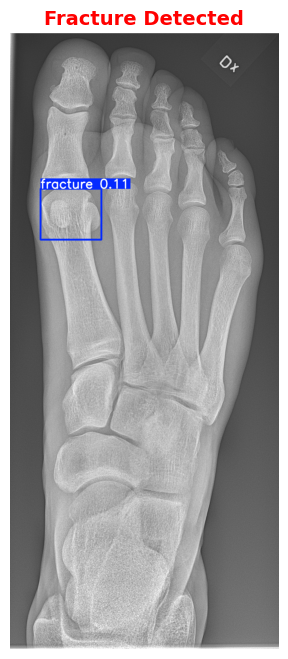


Image: X-ray_of_normal_hand_by_dorsoplantar_projection.jpg - Results
NO FRACTURE DETECTED (Class 0)
The model did not identify any suspicious regions above the confidence threshold of 5%.

Image: X-ray_of_normal_wrist_by_dorsoplantar_projection.jpg - Results
FRACTURE DETECTED (Class 1)
Number of detected regions: 1
   - Detection #1: confidence 11.71%


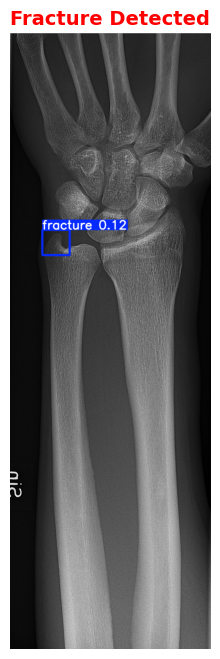


Image: Medical_X-Ray_imaging_MVK06_nevit.jpg - Results
FRACTURE DETECTED (Class 1)
Number of detected regions: 2
   - Detection #1: confidence 49.57%
   - Detection #2: confidence 15.65%


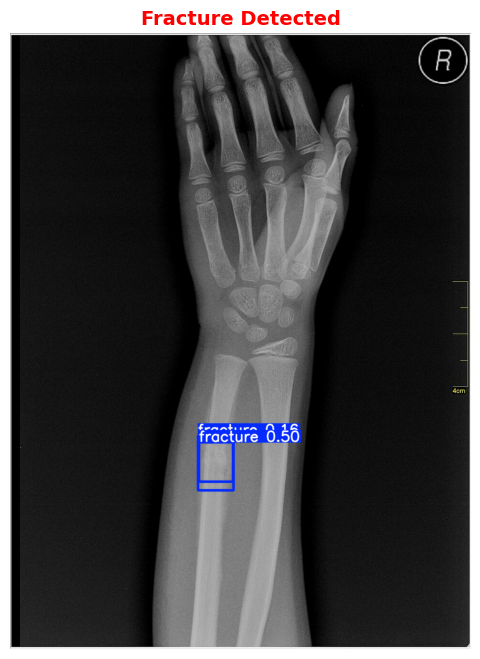


Image: Medical_X-Ray_imaging_MVL06_nevit.jpg - Results
FRACTURE DETECTED (Class 1)
Number of detected regions: 4
   - Detection #1: confidence 48.88%
   - Detection #2: confidence 13.84%
   - Detection #3: confidence 13.33%
   - Detection #4: confidence 6.81%


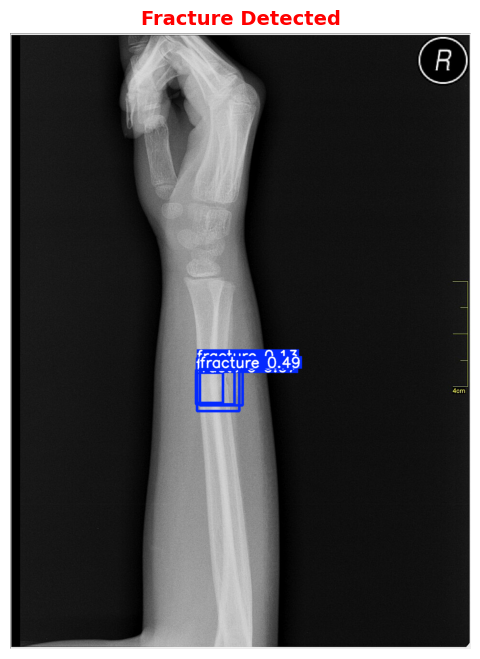

In [ ]:
# Run inference on the test images directory

# Path to the folder with test images, also on Google Drive 
analyze_images("...")